In [1]:
import json
import re

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [22]:
DATA_PATH = Path("../data/raw/readings_weather_station2.txt")

In [38]:

def parse_mongosh_file(file_path):
    """
    Converts a MongoDB mongosh array export into a Pandas DataFrame.
    Supports UUID() and ISODate() values.
    """

    with open(file_path, "r", encoding="utf-8") as file:
        content = file.read()

    # Convert MongoDB-specific constructors into strings
    content = re.sub(
        r"UUID\(['\"]([^'\"]+)['\"]\)",
        r'"\1"',
        content
    )

    content = re.sub(
        r"ISODate\(['\"]([^'\"]+)['\"]\)",
        r'"\1"',
        content
    )

    # Quote unquoted object keys
    content = re.sub(
        r"(?m)^(\s*)([a-zA-Z_$][a-zA-Z0-9_$]*)(\s*:)",
        r'\1"\2"\3',
        content
    )


    # Debug: inspect transformed content before JSON parsing
    #for line_number, line in enumerate(content.splitlines(), start=1):
        #print(f"{line_number:03}: {line}")

    records = json.loads(content)

    # Convert records into a DataFrame
    df = pd.DataFrame(records)

    # Convert timestamps to timezone-aware datetime
    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        utc=True
    )

    # Sort records chronologically
    df = df.sort_values("timestamp").reset_index(drop=True)

    return df

In [765]:
df = parse_mongosh_file(DATA_PATH)

df["timestamp_local"] = (
    df["timestamp"]
    .dt.tz_convert("America/Sao_Paulo")
)

# Ensure sensor measurements are numeric
sensor_columns = [
    "humidity",
    "temperature",
    "visible_ir",
    "infrared",
    "pressure",
    "gas_resistance",
    "soil_moisture_raw"
]

df[sensor_columns] = df[sensor_columns].apply(
    pd.to_numeric,
    errors="coerce"
)

In [766]:
df.head()

,_id,timestamp,humidity,temperature,visible_ir,infrared,pressure,gas_resistance,soil_moisture_raw,timestamp_local
0,de7c2d6c-5251-4133-8ba3-ea6fe69f09d5,2026-11-18 22:42:01.619+00:00,72.66979,28.22575,2,0,1006.76,13.125,2287.05,2026-11-18 19:42:01.619-03:00
1,8accdadd-6612-4d13-98e5-97b374ca5b86,2026-11-18 23:11:41.524+00:00,73.29351,27.97475,2,0,1006.94,12.942,2295.65,2026-11-18 20:11:41.524-03:00
2,b6baf1ff-5043-4186-a93e-baad272e5200,2026-11-18 23:41:19.731+00:00,76.93851,27.69703,2,0,1007.18,13.289,2300.85,2026-11-18 20:41:19.731-03:00
3,3900d02b-8ace-4810-a439-95d453aa1733,2026-11-19 00:10:55.994+00:00,75.67391,27.58488,2,0,1007.72,13.611,2274.50,2026-11-18 21:10:55.994-03:00
4,65a4a385-280c-4d68-8220-a02c8fc26e99,2026-11-19 00:40:31.835+00:00,76.05157,27.52079,2,0,1007.81,13.698,2277.30,2026-11-18 21:40:31.835-03:00


In [767]:
print(f"Total records: {len(df)}")

Total records: 104


In [768]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 104 entries, 0 to 103
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype                            
---  ------             --------------  -----                            
 0   _id                104 non-null    str                              
 1   timestamp          104 non-null    datetime64[us, UTC]              
 2   humidity           104 non-null    float64                          
 3   temperature        104 non-null    float64                          
 4   visible_ir         104 non-null    int64                            
 5   infrared           104 non-null    int64                            
 6   pressure           104 non-null    float64                          
 7   gas_resistance     104 non-null    float64                          
 8   soil_moisture_raw  104 non-null    float64                          
 9   timestamp_local    104 non-null    datetime64[us, America/Sao_Paulo]
dtypes: datetime64

In [769]:
df.describe()

,humidity,temperature,visible_ir,infrared,pressure,gas_resistance,soil_moisture_raw
count,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000,104.000000
mean,70.164564,29.989663,531.730769,529.413462,1005.723365,11.712913,2089.080288
std,6.684791,2.433444,552.457409,554.872812,1.687991,2.649981,353.096034
min,55.930650,26.174940,0.000000,0.000000,1002.490000,7.870000,1282.600000
25%,64.420383,27.682343,1.000000,0.000000,1004.262500,10.071000,2217.550000
50%,70.139660,29.721140,479.000000,482.500000,1006.265000,10.819500,2239.025000
75%,76.537955,32.371445,1048.500000,995.000000,1007.150000,13.369500,2256.725000
max,82.050280,33.747990,1883.000000,1945.000000,1008.200000,18.856000,2407.000000


In [770]:
df.isna().sum()

_id                  0
timestamp            0
humidity             0
temperature          0
visible_ir           0
infrared             0
pressure             0
gas_resistance       0
soil_moisture_raw    0
timestamp_local      0
dtype: int64

In [771]:
print("Duplicated IDs:", df["_id"].duplicated().sum())

Duplicated IDs: 0


In [772]:
print(f"Total records: {len(df)}")
print(f"First reading: {df['timestamp_local'].min()}")
print(f"Last reading:  {df['timestamp_local'].max()}")
print(f"Time span:     {df['timestamp'].max() - df['timestamp'].min()}")

Total records: 104
First reading: 2026-11-18 19:42:01.619000-03:00
Last reading:  2026-11-20 16:50:19.349000-03:00
Time span:     1 days 21:08:17.730000


In [773]:
df["interval_minutes"] = (
    df["timestamp"].diff().dt.total_seconds() / 60
)

df["interval_minutes"].describe()

count    103.000000
mean      26.294131
std        7.374092
min        8.896583
25%       29.592775
50%       29.607833
75%       29.628050
max       29.672700
Name: interval_minutes, dtype: float64

In [774]:

def add_event(timestamp, event_type, notes):
    global events

    # Interpret naive timestamps as Sao Paulo local time
    timestamp = pd.Timestamp(timestamp)

    if timestamp.tzinfo is None:
        timestamp = timestamp.tz_localize(
            "America/Sao_Paulo"
        )
    else:
        timestamp = timestamp.tz_convert(
            "America/Sao_Paulo"
        )

    # Store timestamps in UTC, like MongoDB
    timestamp = timestamp.tz_convert("UTC")

    new_event = pd.DataFrame([{
        "timestamp": timestamp,
        "event_type": event_type,
        "notes": notes
    }])

    events = pd.concat(
        [events, new_event],
        ignore_index=True
    )

    events = (
        events
        .drop_duplicates()
        .sort_values("timestamp")
        .reset_index(drop=True)
    )

    events.to_csv(EVENTS_PATH, index=False)

    return events


In [775]:
EVENTS_PATH = Path("../data/events.csv")

EVENT_COLUMNS = [
    "timestamp",
    "event_type",
    "notes"
]

if EVENTS_PATH.exists():
    events = pd.read_csv(EVENTS_PATH)
    events["timestamp"] = pd.to_datetime(
        events["timestamp"],
        utc=True
    )
else:
    events = pd.DataFrame(columns=EVENT_COLUMNS)

events

,timestamp,event_type,notes
0,2026-11-18 22:30:00+00:00,irrigation,Rega normal em todo o vaso. Horário aproximado.
1,2026-11-18 22:30:00+00:00,sensor_movement,Sensor retirado e inserido novamente no mesmo ...
2,2026-11-19 11:51:00+00:00,irrigation,Rega normal em todo o vaso. Horário aproximado.
3,2026-11-19 18:21:00+00:00,irrigation,Rega normal em todo o vaso. Horário aproximado.
4,2026-11-20 13:05:00+00:00,irrigation,Rega normal em todo o vaso. Horário aproximado.
5,2026-11-20 16:33:00+00:00,sensor_movement,Sensor removido e inserido mais para o centro ...
6,2026-11-20 16:47:00+00:00,irrigation,Focused irrigation around sensor.


In [776]:

def plot_sensor_with_events(data, column, title, ylabel, events):
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        data["timestamp_local"],
        data[column],
        marker=".",
        markersize=4,
        label=column
    )

    event_types = events["event_type"].dropna().unique()

    for event_type in event_types:
        selected = events[
            events["event_type"] == event_type
        ]

        for _, event in selected.iterrows():
            event_time = event["timestamp"].tz_convert(
                "America/Sao_Paulo"
            )

            ax.axvline(
                event_time,
                linestyle="--",
                alpha=0.7,
                label=event_type
            )

    ax.set_title(title)
    ax.set_xlabel("Timestamp")
    ax.set_ylabel(ylabel)
    ax.grid(True)
    ax.legend()
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


In [777]:

def plot_sensor_with_events(data, column, title, ylabel, events):

    fig, ax = plt.subplots(figsize=(15, 6))

    ax.plot(
        data["timestamp_local"],
        data[column],
        marker=".",
        markersize=4,
        label=column
    )

    event_styles = {
        "irrigation": {
            "linestyle": "--",
            "color": "tab:blue"
        },
        "sensor_movement": {
            "linestyle": ":",
            "color": "tab:red"
        }
    }

    for event_type, group in events.groupby("event_type"):

        style = event_styles.get(
            event_type,
            {"linestyle": "--", "color": "gray"}
        )

        for i, (_, event) in enumerate(group.iterrows()):

            event_time = pd.Timestamp(
                event["timestamp"]
            ).tz_convert("America/Sao_Paulo")

            ax.axvline(
                event_time,
                label=event_type if i == 0 else None,
                alpha=0.8,
                **style
            )

    ax.set_title(title)
    ax.set_xlabel("Timestamp (local)")
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)
    ax.legend()

    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()


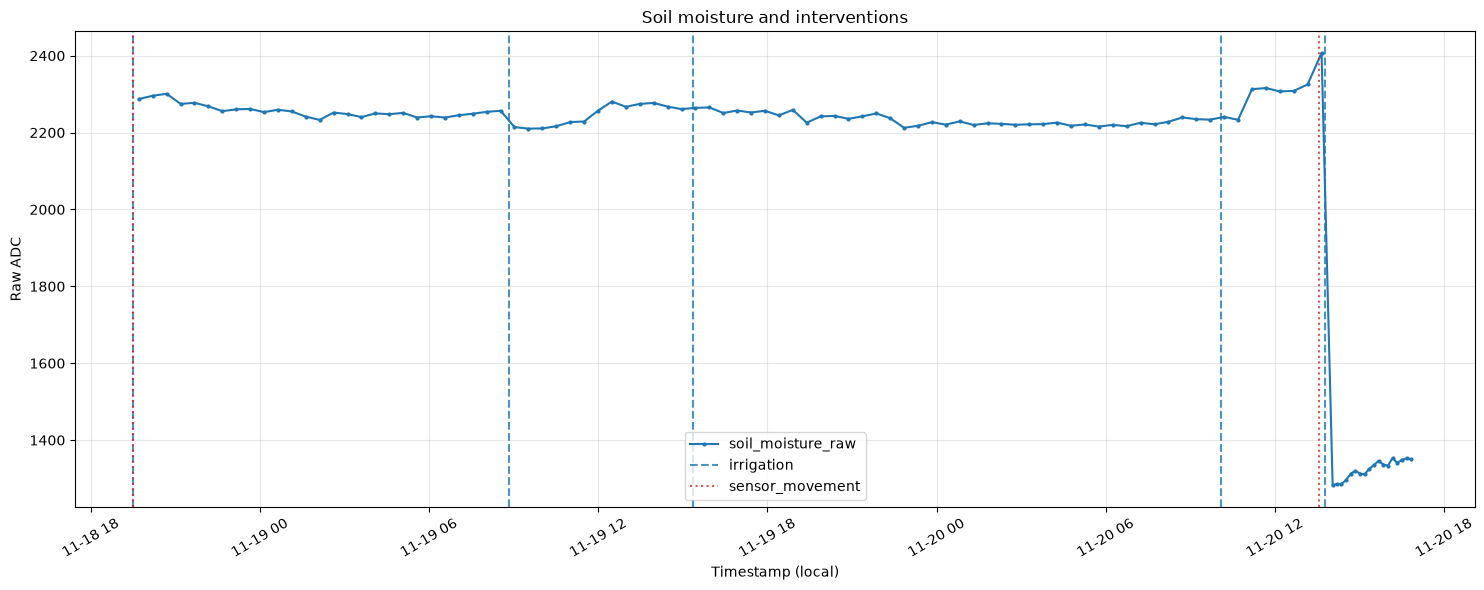

In [778]:
plot_sensor_with_events(
    df,
    "soil_moisture_raw",
    "Soil moisture and interventions",
    "Raw ADC",
    events
)

In [779]:
def classify_interval(minutes):
    if pd.isna(minutes):
        return "first_reading"
    elif minutes < 25:
        return "manual_or_early_reading"
    elif minutes <= 35:
        return "normal"
    else:
        return "collection_gap"


df["interval_status"] = df["interval_minutes"].apply(
    classify_interval
)

df["interval_status"].value_counts()

interval_status
normal                     85
manual_or_early_reading    18
first_reading               1
Name: count, dtype: int64

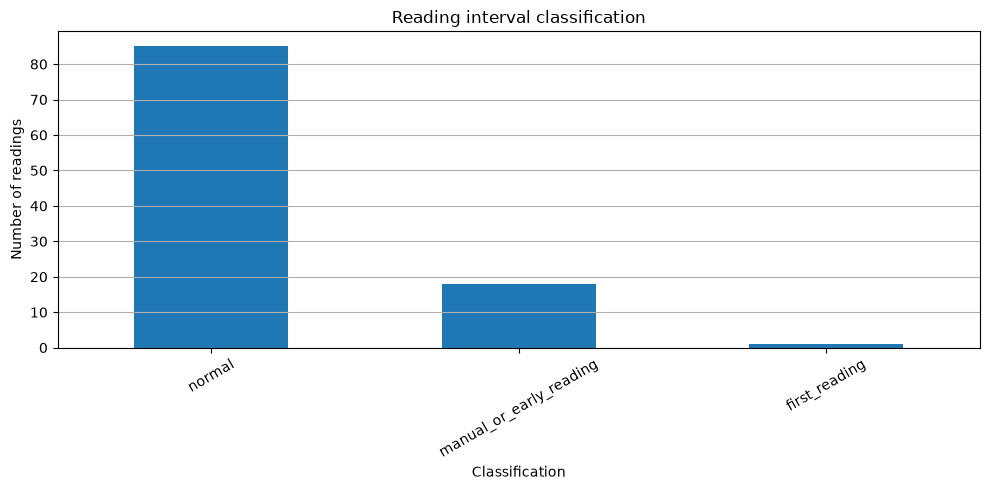

In [780]:
interval_counts = df["interval_status"].value_counts()

interval_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Reading interval classification")
plt.xlabel("Classification")
plt.ylabel("Number of readings")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

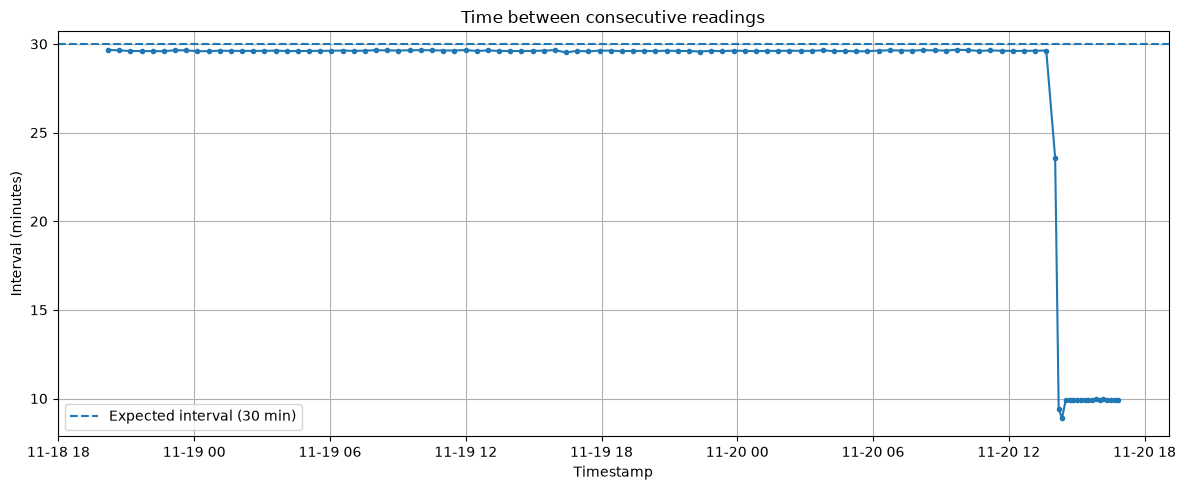

In [781]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["timestamp_local"],
    df["interval_minutes"],
    marker=".",
    linestyle="-"
)

plt.axhline(
    30,
    linestyle="--",
    label="Expected interval (30 min)"
)

plt.title("Time between consecutive readings")
plt.xlabel("Timestamp")
plt.ylabel("Interval (minutes)")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

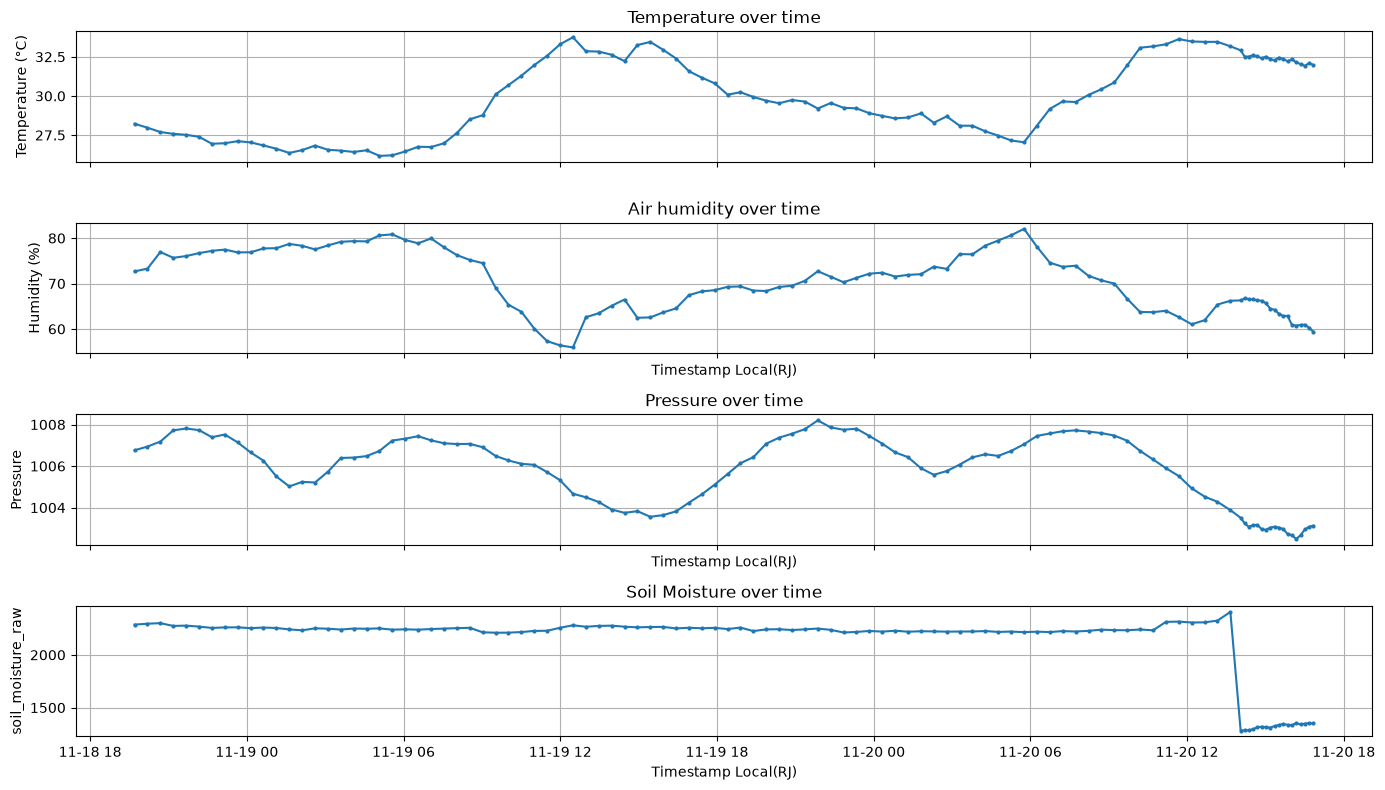

In [782]:
fig, axes = plt.subplots(
    4, 1,
    figsize=(14, 8),
    sharex=True
)

axes[0].plot(
    df["timestamp_local"],
    df["temperature"],
    marker=".",
    markersize=4
)

axes[0].set_title("Temperature over time")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(True)

axes[1].plot(
    df["timestamp_local"],
    df["humidity"],
    marker=".",
    markersize=4
)

axes[1].set_title("Air humidity over time")
axes[1].set_ylabel("Humidity (%)")
axes[1].set_xlabel("Timestamp Local(RJ)")
axes[1].grid(True)

axes[2].plot(
    df["timestamp_local"],
    df["pressure"],
    marker=".",
    markersize=4
)

axes[2].set_title("Pressure over time")
axes[2].set_ylabel("Pressure")
axes[2].set_xlabel("Timestamp Local(RJ)")
axes[2].grid(True)

axes[3].plot(
    df["timestamp_local"],
    df["soil_moisture_raw"],
    marker=".",
    markersize=4
)

axes[3].set_title("Soil Moisture over time")
axes[3].set_ylabel("soil_moisture_raw")
axes[3].set_xlabel("Timestamp Local(RJ)")
axes[3].grid(True)

plt.tight_layout()
plt.show()

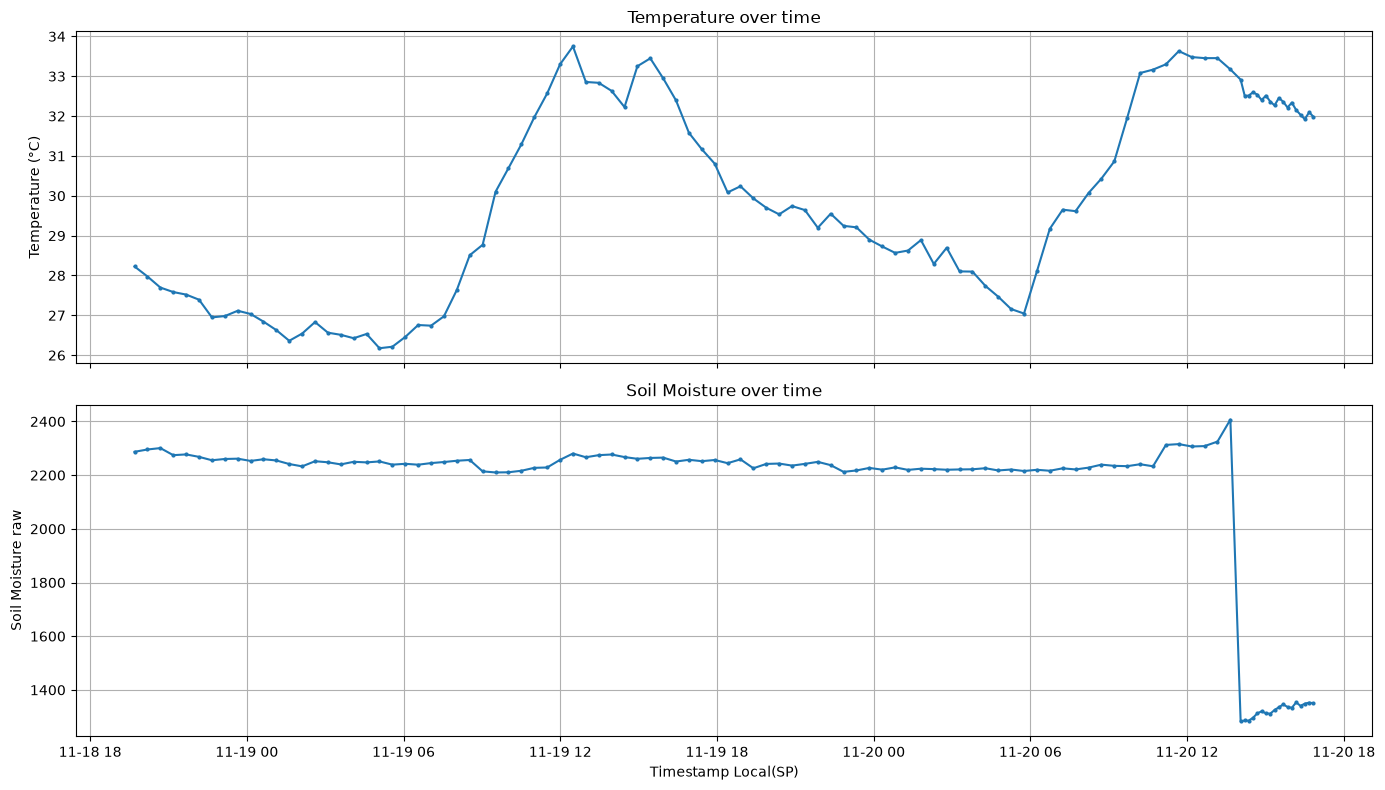

In [783]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

axes[0].plot(
    df["timestamp_local"],
    df["temperature"],
    marker=".",
    markersize=4
)

axes[0].set_title("Temperature over time")
axes[0].set_ylabel("Temperature (°C)")
axes[0].grid(True)

axes[1].plot(
    df["timestamp_local"],
    df["soil_moisture_raw"],
    marker=".",
    markersize=4
)

axes[1].set_title("Soil Moisture over time")
axes[1].set_ylabel("Soil Moisture raw")
axes[1].set_xlabel("Timestamp Local(SP)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

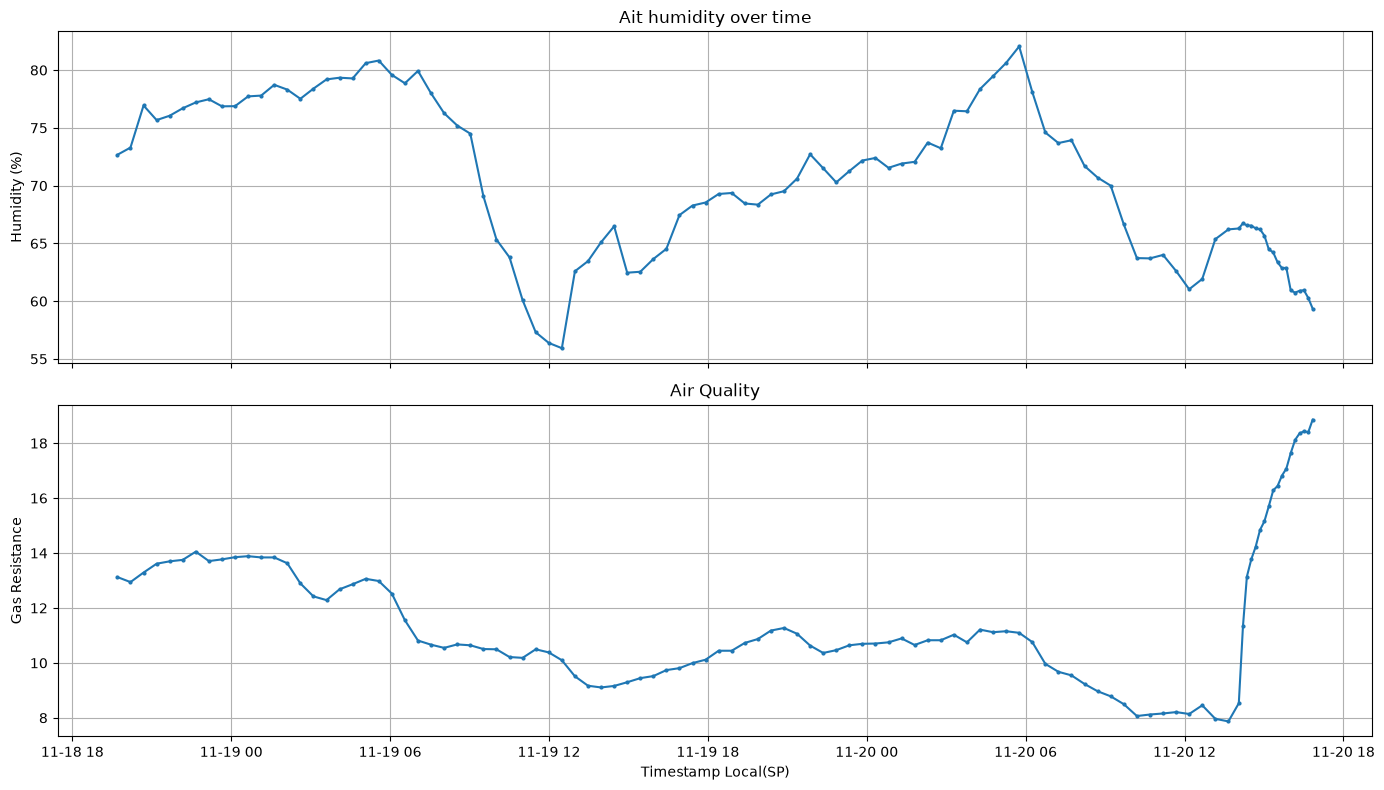

In [784]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 8),
    sharex=True
)

axes[0].plot(
    df["timestamp_local"],
    df["humidity"],
    marker=".",
    markersize=4
)

axes[0].set_title("Ait humidity over time")
axes[0].set_ylabel("Humidity (%)")
axes[0].grid(True)

axes[1].plot(
    df["timestamp_local"],
    df["gas_resistance"],
    marker=".",
    markersize=4
)

axes[1].set_title("Air Quality")
axes[1].set_ylabel("Gas Resistance")
axes[1].set_xlabel("Timestamp Local(SP)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [785]:

correlation_columns = [
    "soil_moisture_raw",
    "temperature",
    "humidity"
]

# Linear correlation
pearson_corr = df[correlation_columns].corr(
    method="pearson"
)

# Monotonic correlation
spearman_corr = df[correlation_columns].corr(
    method="spearman"
)

print("Pearson correlation:")
display(pearson_corr.round(3))

print("Spearman correlation:")
display(spearman_corr.round(3))


Pearson correlation:


,soil_moisture_raw,temperature,humidity
soil_moisture_raw,1.000,-0.418,0.423
temperature,-0.418,1.000,-0.943
humidity,0.423,-0.943,1.000


Spearman correlation:


,soil_moisture_raw,temperature,humidity
soil_moisture_raw,1.000,-0.053,0.109
temperature,-0.053,1.000,-0.923
humidity,0.109,-0.923,1.000


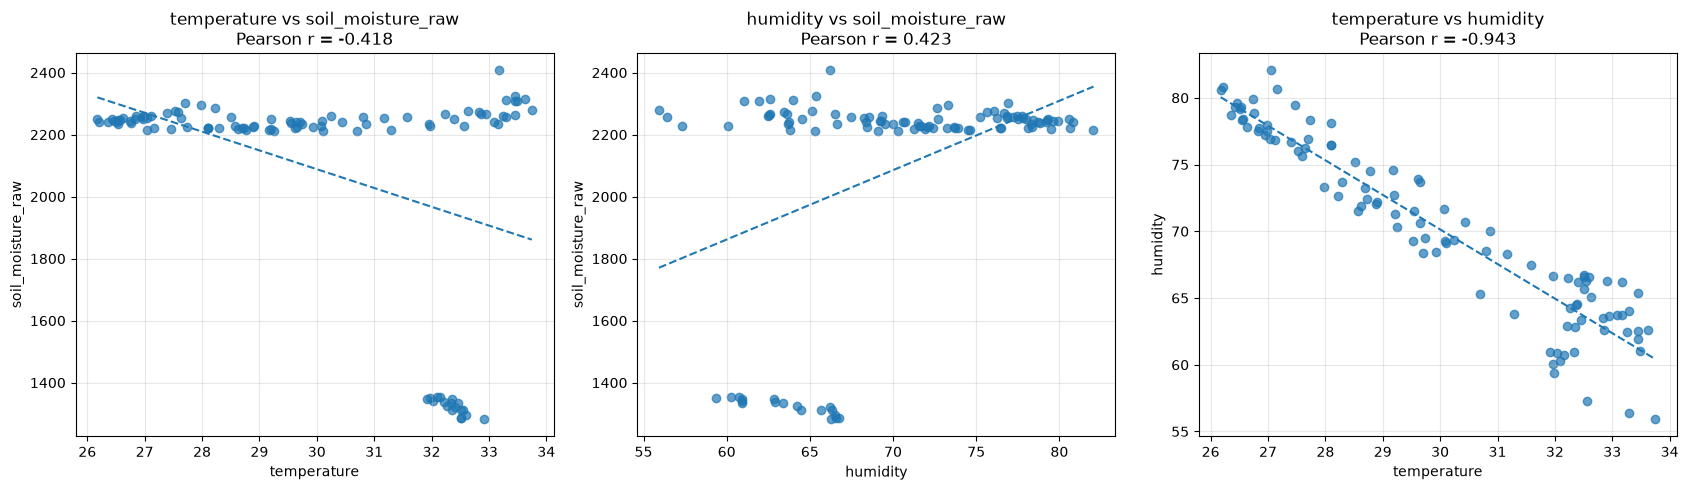

In [786]:

import numpy as np

relationships = [
    ("temperature", "soil_moisture_raw"),
    ("humidity", "soil_moisture_raw"),
    ("temperature", "humidity")
]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (x, y) in zip(axes, relationships):

    valid = df[[x, y]].dropna()

    ax.scatter(
        valid[x],
        valid[y],
        alpha=0.7
    )

    if len(valid) >= 2:
        slope, intercept = np.polyfit(
            valid[x],
            valid[y],
            1
        )

        x_line = np.linspace(
            valid[x].min(),
            valid[x].max(),
            100
        )

        ax.plot(
            x_line,
            slope * x_line + intercept,
            linestyle="--"
        )

    correlation = valid[x].corr(valid[y])

    ax.set_title(
        f"{x} vs {y}\nPearson r = {correlation:.3f}"
    )

    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
